In [67]:
import os
import random
import warnings
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.tree import plot_tree
from scipy.stats import shapiro
import itertools
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH = Path("data")
FIG_DIR = Path("results/figures")
LOG_DIR = Path("logs/fit")
for p in [DATA_PATH, FIG_DIR, LOG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
!wget -O heart_failure_clinical_records_dataset.csv https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/heart_failure_clinical_records_dataset.csv

--2026-11-01 05:36:45--  https://raw.githubusercontent.com/Turbonik/Data-Analysis/main/heart_failure_clinical_records_dataset.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12239 (12K) [text/plain]
Saving to: ‘heart_failure_clinical_records_dataset.csv’

heart_failure_clini 100%[===================>]  11.95K  --.-KB/s    in 0s      

2026-11-01 05:36:45 (99.2 MB/s) - ‘heart_failure_clinical_records_dataset.csv’ saved [12239/12239]



## Дискриптивный анализ

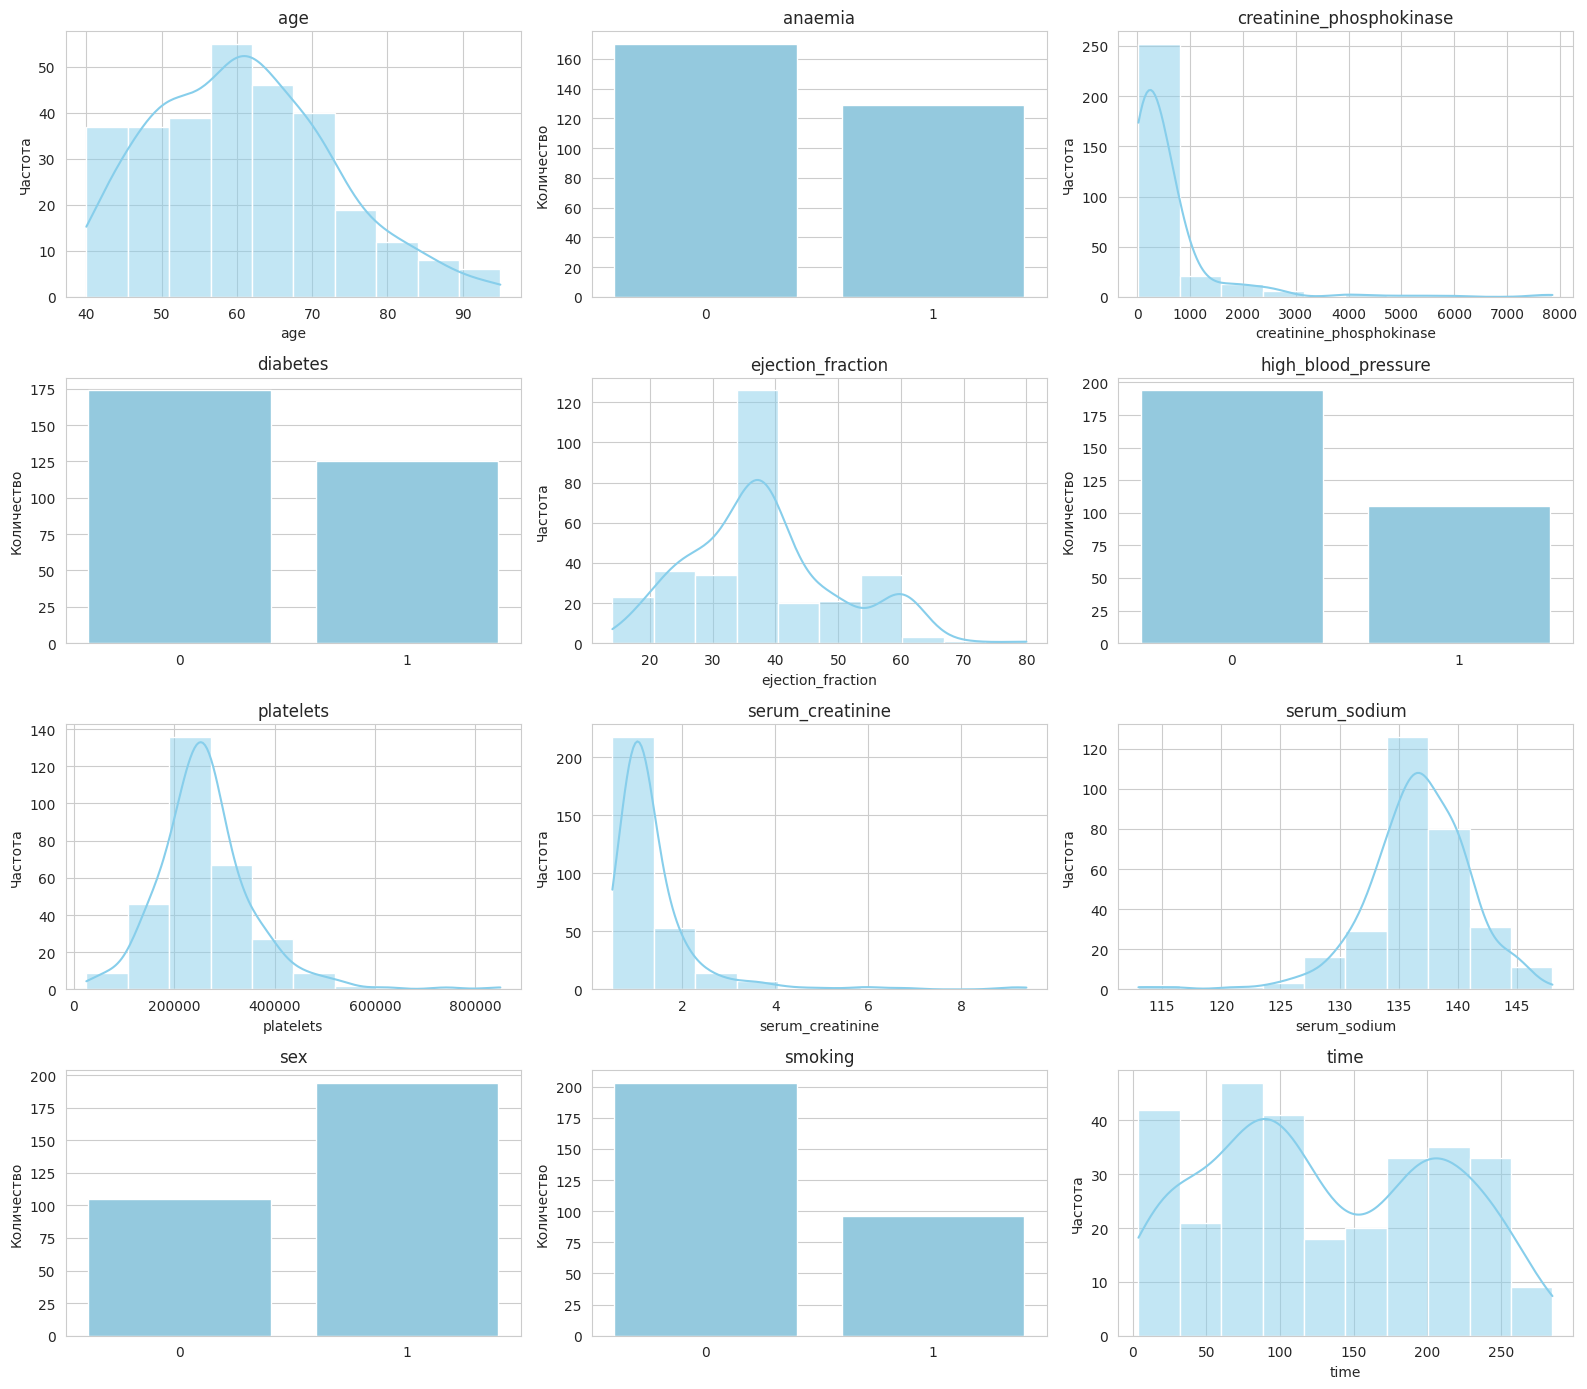

In [68]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

features = df.drop(columns=['DEATH_EVENT']).columns
categorical_features = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

n = len(df)
bins = int(np.ceil(1 + np.log2(n)))

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(features):
    if col in categorical_features:
        sns.countplot(data=df, x=col, ax=axes[i], color='skyblue')
        axes[i].set_title(f'{col}')
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Количество')
    else:
        sns.histplot(df[col], bins=bins, kde=True, ax=axes[i], color='skyblue')
        stat, p_value = shapiro(df[col])
        axes[i].set_title(f'{col}')
        axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

In [69]:
dead_times = df[df['DEATH_EVENT'] == 1]['time']

median_time = dead_times.median()
print(f"Медиана времени смерти: {median_time}")

print("\nКвантили времени смерти (25%, 50%, 75%):")
print(dead_times.quantile([0.25, 0.5, 0.75]))

df['TARGET'] = 0
df.loc[(df['DEATH_EVENT'] == 1) & (df['time'] <= 45), 'TARGET'] = 1
df.loc[(df['DEATH_EVENT'] == 1) & (df['time'] > 45), 'TARGET'] = 2

X = df.drop(columns=['DEATH_EVENT', 'time', 'TARGET'])
y = df['TARGET']

print("Распределение по 3 классам (0-выжил, 1-умер рано, 2-умер поздно):")
print(y.value_counts())

Медиана времени смерти: 44.5

Квантили времени смерти (25%, 50%, 75%):
0.25     25.50
0.50     44.50
0.75    102.25
Name: time, dtype: float64
Распределение по 3 классам (0-выжил, 1-умер рано, 2-умер поздно):
TARGET
0    203
1     49
2     47
Name: count, dtype: int64


## Выбор наиболее информативных признаков

In [70]:

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

df['TARGET'] = 0
df.loc[(df['DEATH_EVENT'] == 1) & (df['time'] <= 45), 'TARGET'] = 1
df.loc[(df['DEATH_EVENT'] == 1) & (df['time'] > 45), 'TARGET'] = 2

X = df.drop(columns=['DEATH_EVENT', 'time', 'TARGET'])
y = df['TARGET']

selector = SelectKBest(score_func=f_classif, k=5)
selector.fit(X, y)

scores = pd.DataFrame({
    'Признак': X.columns,
    'F-оценка (Fisher score)': selector.scores_,
    'p-value': selector.pvalues_
}).sort_values(by='F-оценка (Fisher score)', ascending=False)

print("Рейтинг признаков по критерию Фишера:")
print(scores)

X_selected = X[X.columns[selector.get_support()]]
print("\nВыбранные 5 признаков:")
print(X_selected.columns.tolist())

Рейтинг признаков по критерию Фишера:
                     Признак  F-оценка (Fisher score)       p-value
4          ejection_fraction                14.653236  8.547772e-07
7           serum_creatinine                14.531313  9.551059e-07
0                        age                11.721269  1.261963e-05
8               serum_sodium                 5.909578  3.043814e-03
5        high_blood_pressure                 3.355906  3.620985e-02
1                    anaemia                 1.712266  1.822389e-01
2   creatinine_phosphokinase                 1.292964  2.760016e-01
3                   diabetes                 0.568730  5.668617e-01
6                  platelets                 0.433120  6.488932e-01
10                   smoking                 0.068354  9.339448e-01
9                        sex                 0.014118  9.859822e-01

Выбранные 5 признаков:
['age', 'ejection_fraction', 'high_blood_pressure', 'serum_creatinine', 'serum_sodium']


## Диаграммы рассеивания

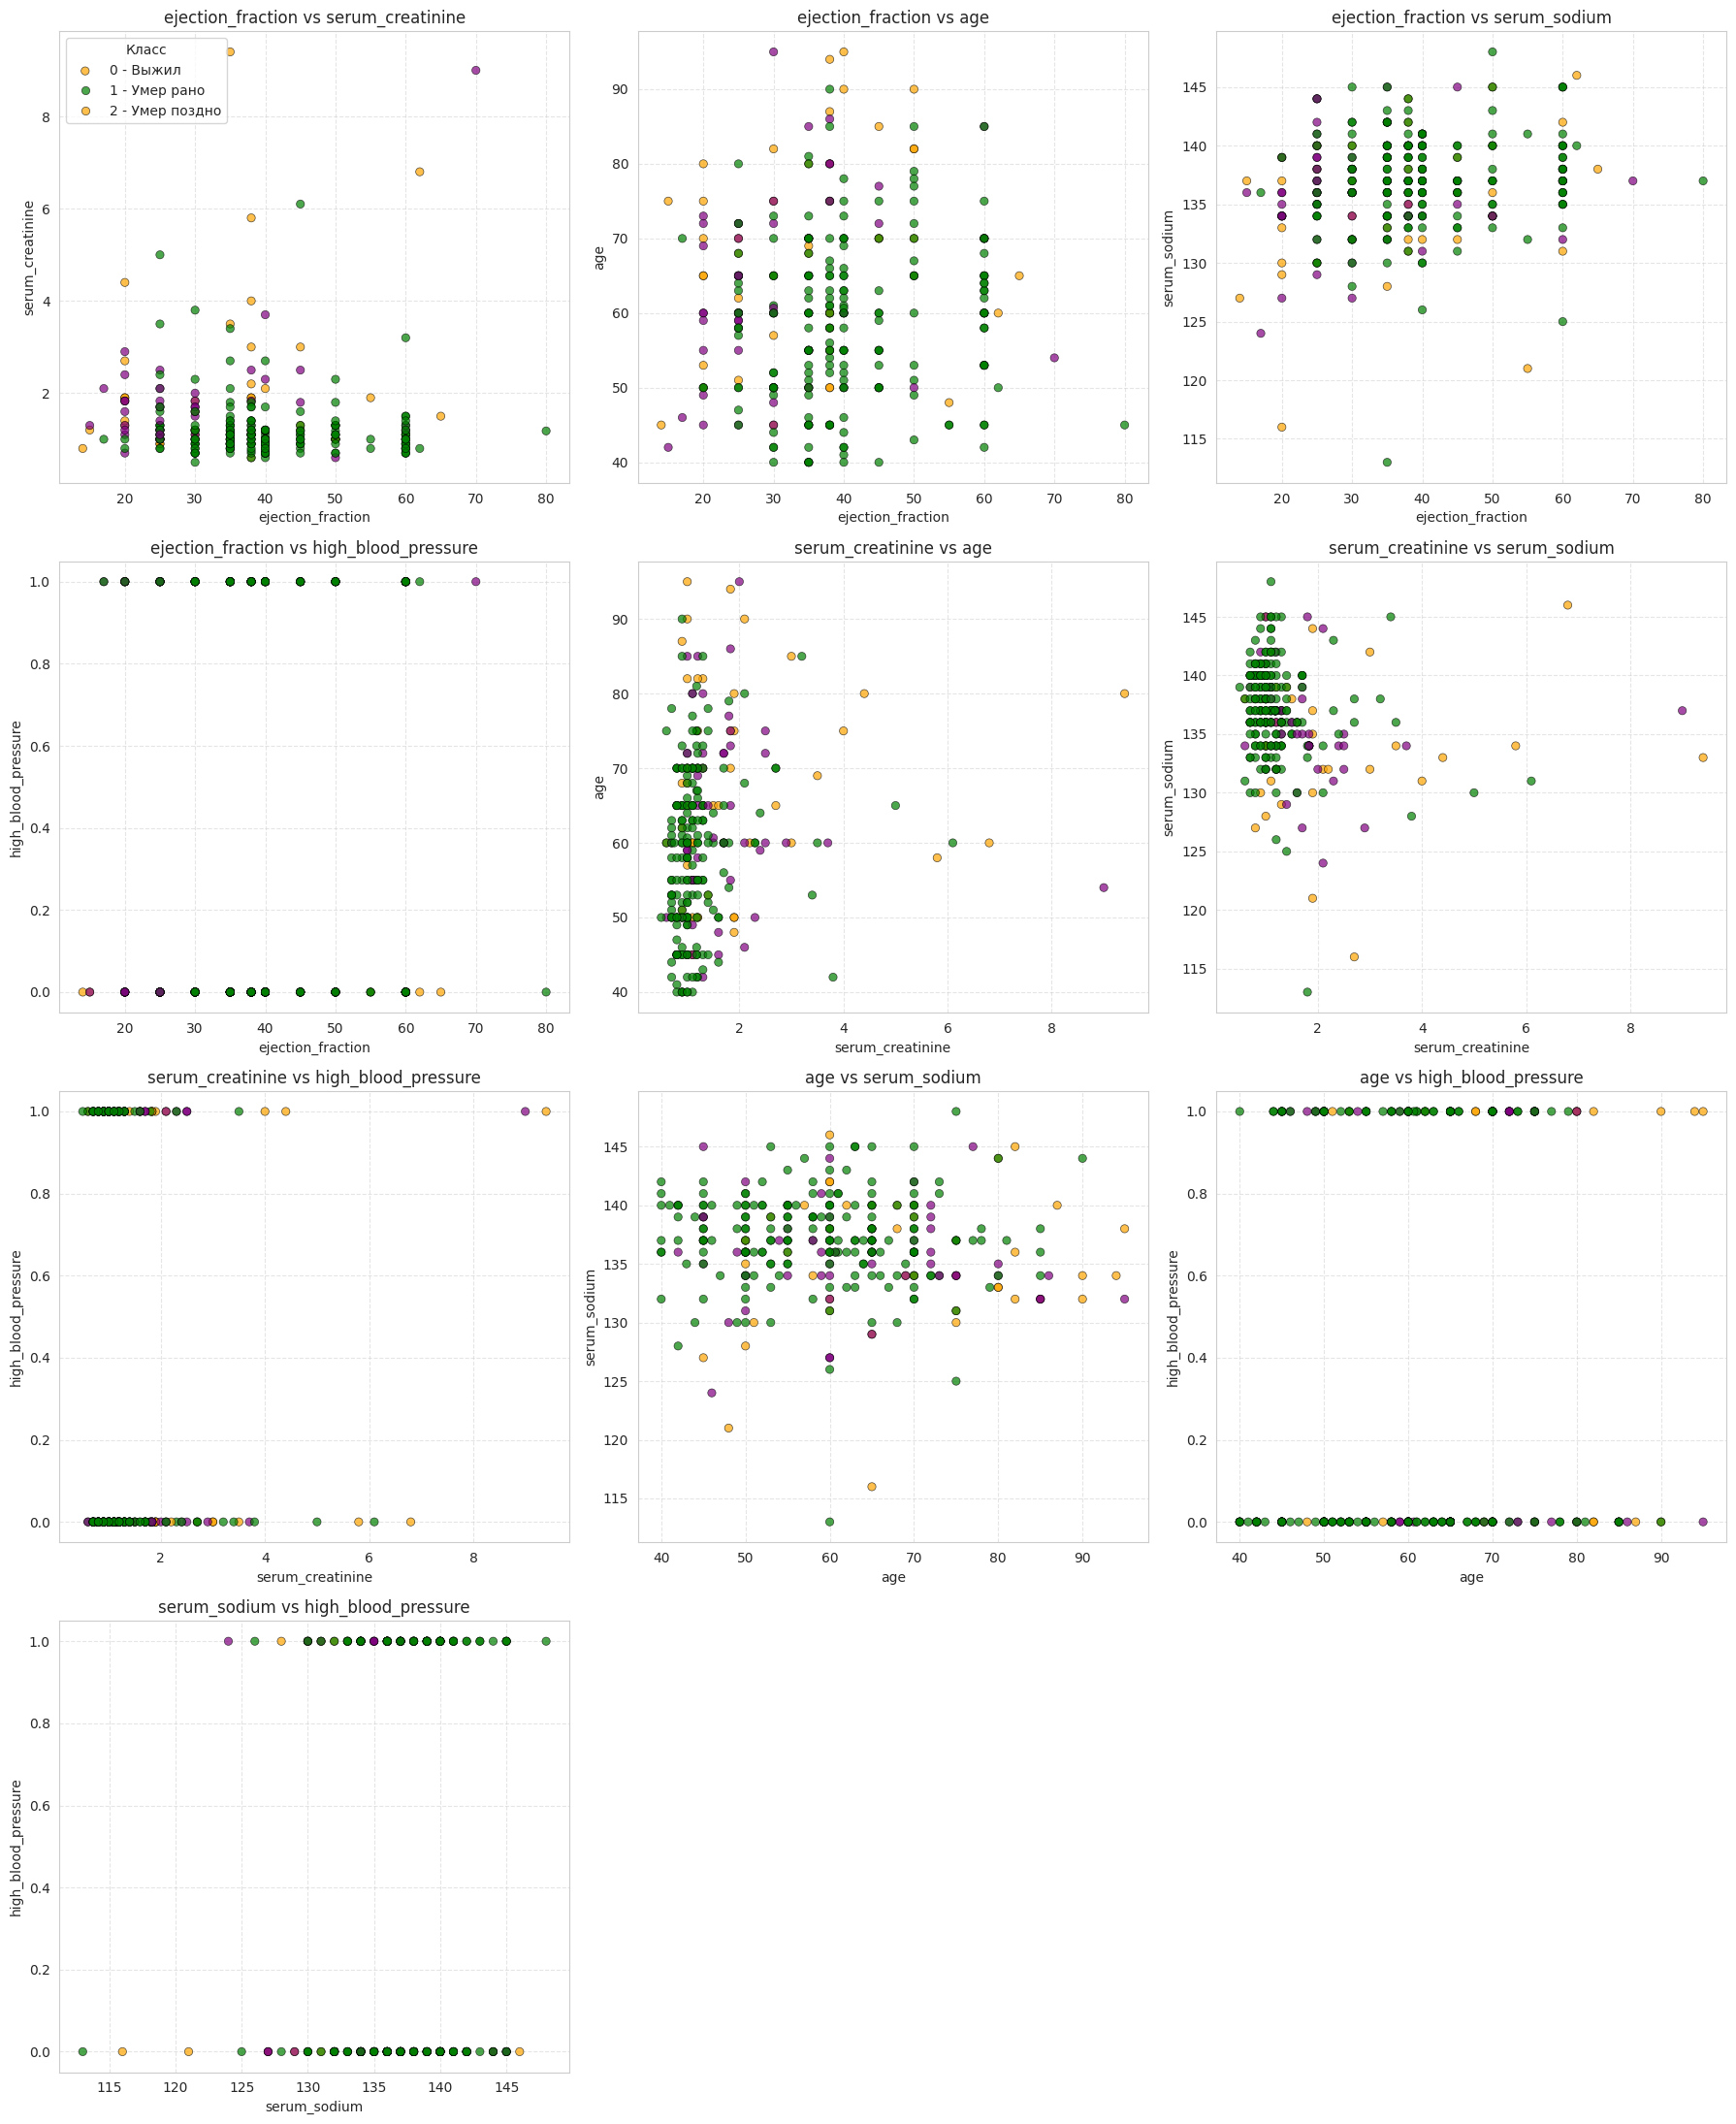

In [71]:
top_features = ['ejection_fraction', 'serum_creatinine', 'age', 'serum_sodium', 'high_blood_pressure']
combinations = list(itertools.combinations(top_features, 2))

fig, axes = plt.subplots(4, 3, figsize=(18, 22))
axes = axes.flatten()

for i, (x_col, y_col) in enumerate(combinations):
    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col,
        hue='TARGET',
        palette=['green', 'orange', 'purple'],
        alpha=0.7,
        edgecolor='k',
        ax=axes[i]
    )
    axes[i].set_title(f'{x_col} vs {y_col}', fontsize=12)
    axes[i].set_xlabel(x_col)
    axes[i].set_ylabel(y_col)
    axes[i].grid(True, linestyle='--', alpha=0.5)

    if i == 0:
        axes[i].legend(title='Класс', labels=['0 - Выжил', '1 - Умер рано', '2 - Умер поздно'])
    else:
        axes[i].get_legend().remove()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## Разбиение выборки

In [72]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['DEATH_EVENT', 'time', 'TARGET'])
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Обучающая выборка (Train): {X_train.shape[0]} объектов")
print(f"Тестовая выборка (Test): {X_test.shape[0]} объектов")
print("\nРаспределение классов в Train:")
print(y_train.value_counts(normalize=True).round(3))
print("\nРаспределение классов в Test:")
print(y_test.value_counts(normalize=True).round(3))

Обучающая выборка (Train): 239 объектов
Тестовая выборка (Test): 60 объектов

Распределение классов в Train:
TARGET
0    0.678
1    0.163
2    0.159
Name: proportion, dtype: float64

Распределение классов в Test:
TARGET
0    0.683
1    0.167
2    0.150
Name: proportion, dtype: float64


--- kNN | Train (distance) ---
Accuracy: 1.000
Macro F1: 1.000
Macro Recall: 1.000
ROC-AUC: 1.000

--- kNN | Test (distance) ---
Accuracy: 0.600
Macro F1: 0.253
Macro Recall: 0.293
ROC-AUC: 0.745

--- Tree | Train (depth=4) ---
Accuracy: 0.778
Macro F1: 0.654
Macro Recall: 0.621
ROC-AUC: 0.848

--- Tree | Test (depth=4) ---
Accuracy: 0.633
Macro F1: 0.449
Macro Recall: 0.446
ROC-AUC: 0.650



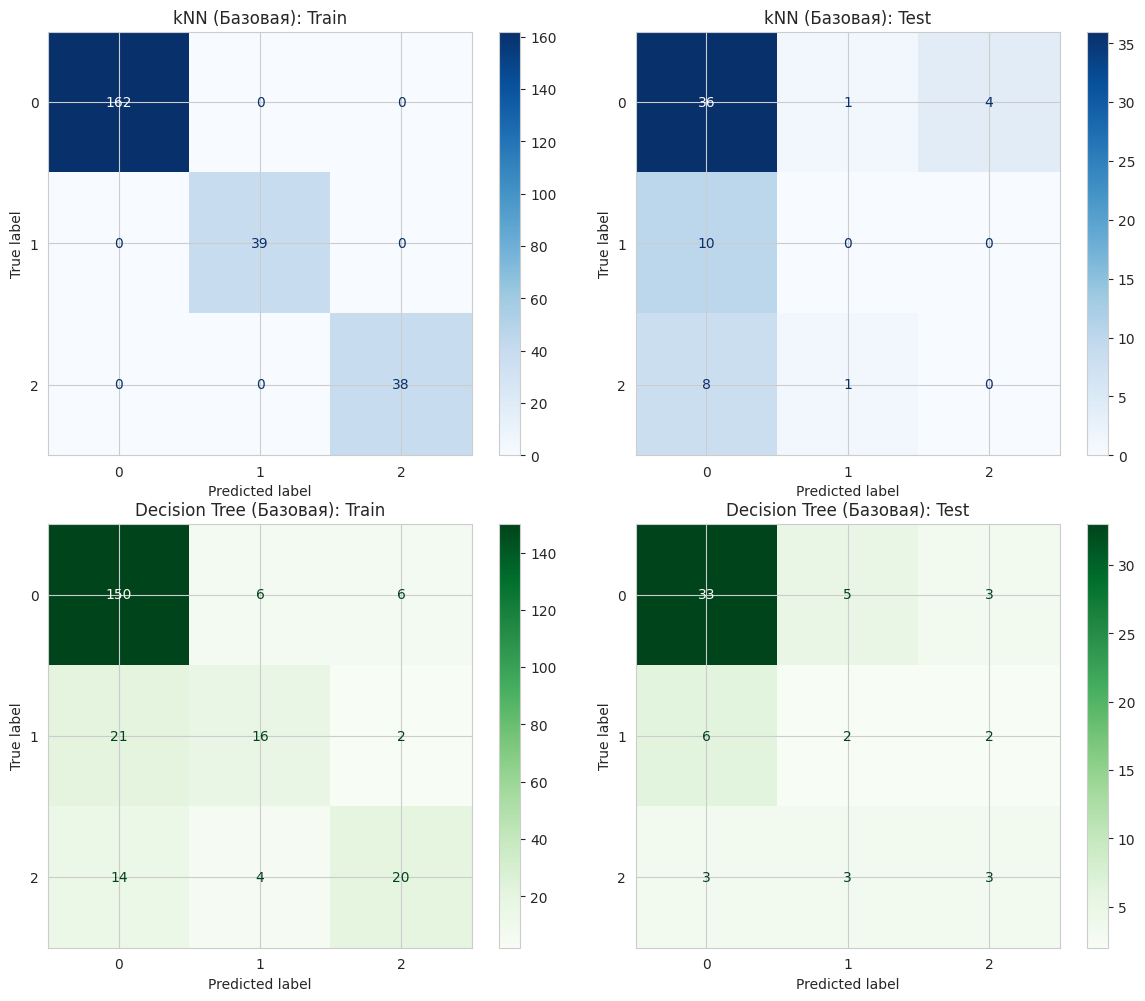

In [79]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

base_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, weights='distance'))
])
base_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)

base_knn.fit(X_train, y_train)
base_tree.fit(X_train, y_train)

y_pred_knn_train = base_knn.predict(X_train)
y_proba_knn_train = base_knn.predict_proba(X_train)
y_pred_knn_test = base_knn.predict(X_test)
y_proba_knn_test = base_knn.predict_proba(X_test)

y_pred_tree_train = base_tree.predict(X_train)
y_proba_tree_train = base_tree.predict_proba(X_train)
y_pred_tree_test = base_tree.predict(X_test)
y_proba_tree_test = base_tree.predict_proba(X_test)

def print_metrics(y_true, y_pred, y_proba, name):
    print(f"--- {name} ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}")
    print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(f"Macro Recall: {recall_score(y_true, y_pred, average='macro'):.3f}")
    print(f"ROC-AUC: {roc_auc_score(y_true, y_proba, multi_class='ovr'):.3f}\n")

print_metrics(y_train, y_pred_knn_train, y_proba_knn_train, "kNN | Train (distance)")
print_metrics(y_test, y_pred_knn_test, y_proba_knn_test, "kNN | Test (distance)")
print_metrics(y_train, y_pred_tree_train, y_proba_tree_train, "Tree | Train (depth=4)")
print_metrics(y_test, y_pred_tree_test, y_proba_tree_test, "Tree | Test (depth=4)")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_knn_train, ax=axes[0, 0], cmap='Blues')
axes[0, 0].set_title('kNN (Базовая): Train')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn_test, ax=axes[0, 1], cmap='Blues')
axes[0, 1].set_title('kNN (Базовая): Test')

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_tree_train, ax=axes[1, 0], cmap='Greens')
axes[1, 0].set_title('Decision Tree (Базовая): Train')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree_test, ax=axes[1, 1], cmap='Greens')
axes[1, 1].set_title('Decision Tree (Базовая): Test')
plt.tight_layout()
plt.show()

## Влияние изменения параметров

In [74]:

print("--- Исследование kNN ---")
knn_results = []
for k in [3, 5, 7, 9, 11]:
    for w in ['uniform', 'distance']:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('knn', KNeighborsClassifier(n_neighbors=k, weights=w))
        ])
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        knn_results.append({
            'k': k,
            'weights': w,
            'Macro_F1': f1_score(y_test, y_pred, average='macro'),
            'Macro_Recall': recall_score(y_test, y_pred, average='macro')
        })
df_knn = pd.DataFrame(knn_results).sort_values(by='Macro_F1', ascending=False)
display(df_knn.head(5))

print("\n--- Исследование Decision Tree ---")
tree_results = []
for depth in [2, 3, 4, 5, 7]:
    for min_leaf in [1, 3, 5]:
        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            class_weight='balanced',
            random_state=42
        )
        tree.fit(X_train, y_train)
        y_pred = tree.predict(X_test)

        tree_results.append({
            'max_depth': depth,
            'min_samples_leaf': min_leaf,
            'Macro_F1': f1_score(y_test, y_pred, average='macro'),
            'Macro_Recall': recall_score(y_test, y_pred, average='macro')
        })
df_tree = pd.DataFrame(tree_results).sort_values(by='Macro_F1', ascending=False)
display(df_tree.head(5))

--- Исследование kNN ---


,k,weights,Macro_F1,Macro_Recall
2,5,uniform,0.317551,0.337850
0,3,uniform,0.317123,0.345980
1,3,distance,0.309783,0.337850
8,11,uniform,0.270627,0.333333
9,11,distance,0.266667,0.325203



--- Исследование Decision Tree ---


,max_depth,min_samples_leaf,Macro_F1,Macro_Recall
14,7,5,0.434364,0.455827
13,7,3,0.398148,0.410659
11,5,5,0.396047,0.401716
9,5,1,0.382001,0.380939
8,4,5,0.377167,0.394399


## Лучшие параметры

--- kNN (k=5) ---
Accuracy: 0.633
Macro F1: 0.318
Micro F1: 0.633
Macro Recall: 0.338
ROC-AUC (OvR): 0.737

--- Decision Tree (depth=7) ---
Accuracy: 0.550
Macro F1: 0.434
Micro F1: 0.550
Macro Recall: 0.456
ROC-AUC (OvR): 0.602



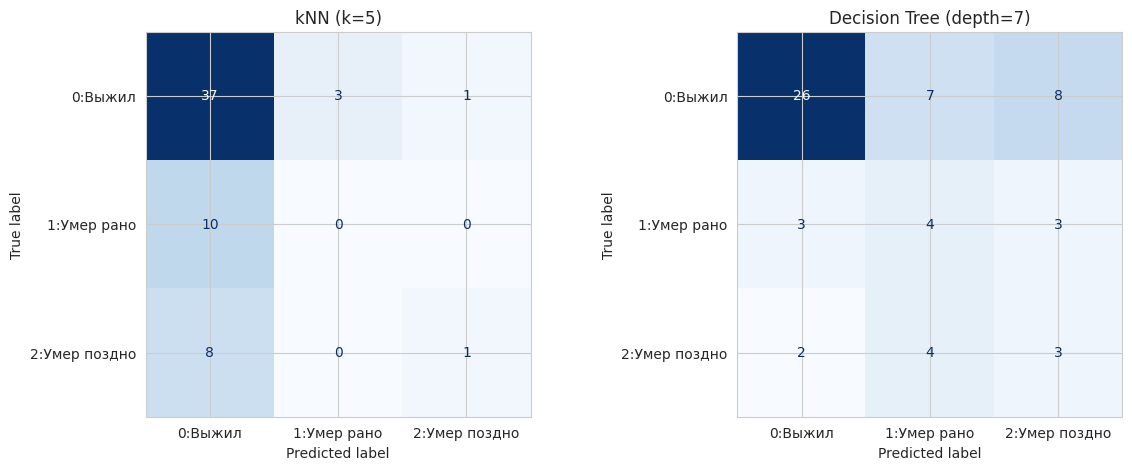

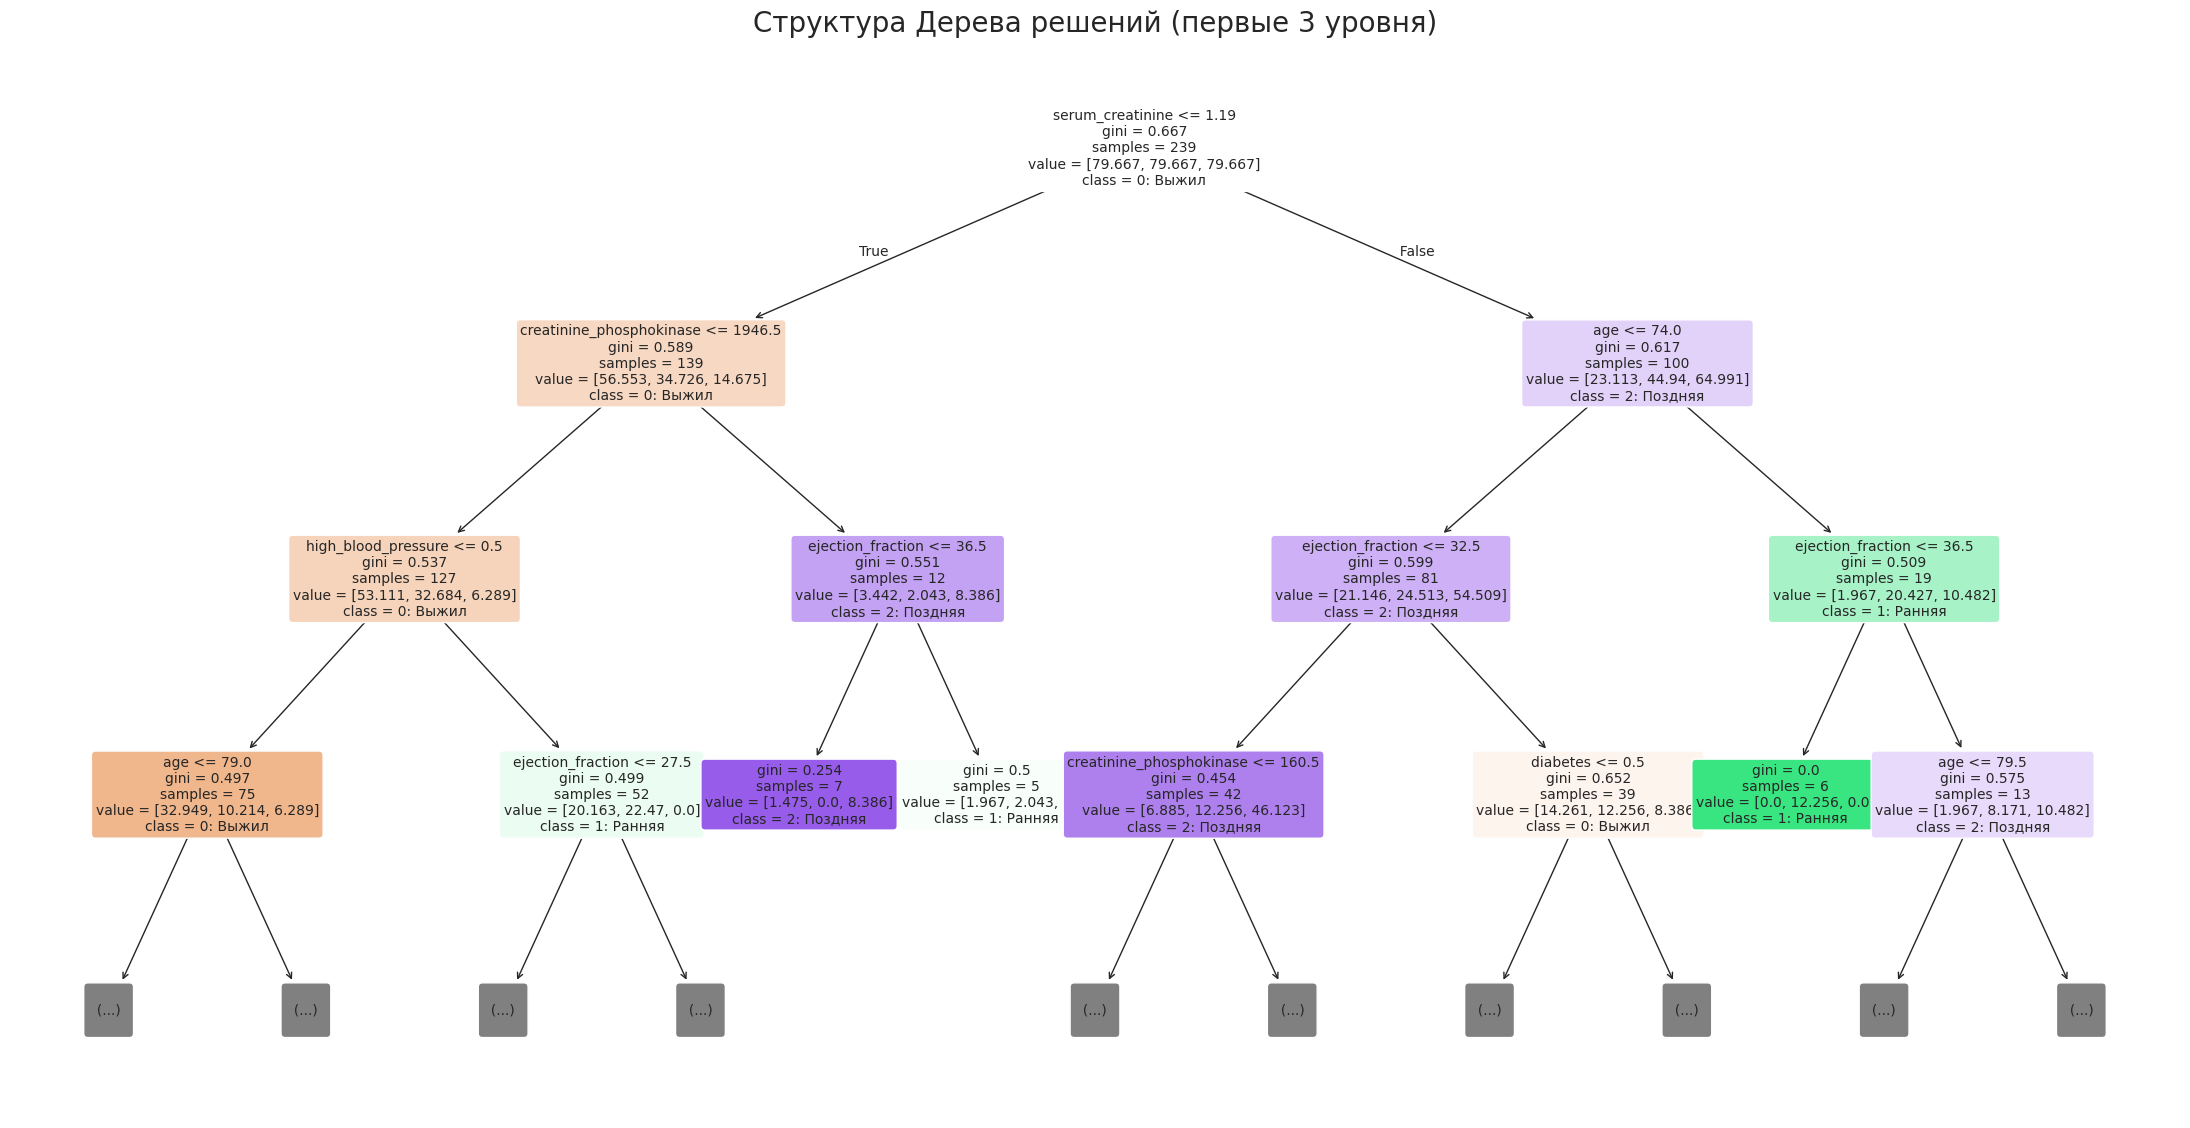

<Figure size 640x480 with 0 Axes>

In [75]:

final_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, weights='uniform'))
])

final_tree = DecisionTreeClassifier(
    max_depth=7,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

final_knn.fit(X_train, y_train)
final_tree.fit(X_train, y_train)

y_pred_knn = final_knn.predict(X_test)
y_proba_knn = final_knn.predict_proba(X_test)

y_pred_tree = final_tree.predict(X_test)
y_proba_tree = final_tree.predict_proba(X_test)

def evaluate_and_plot(y_true, y_pred, y_proba, name, ax):
    print(f"--- {name} ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}")
    print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(f"Micro F1: {f1_score(y_true, y_pred, average='micro'):.3f}")
    print(f"Macro Recall: {recall_score(y_true, y_pred, average='macro'):.3f}")
    print(f"ROC-AUC (OvR): {roc_auc_score(y_true, y_proba, multi_class='ovr'):.3f}\n")

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0:Выжил', '1:Умер рано', '2:Умер поздно'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
evaluate_and_plot(y_test, y_pred_knn, y_proba_knn, "kNN (k=5)", axes[0])
evaluate_and_plot(y_test, y_pred_tree, y_proba_tree, "Decision Tree (depth=7)", axes[1])

plt.figure(figsize=(28, 14))

plot_tree(
    final_tree,
    max_depth=3,
    feature_names=X.columns,
    class_names=['0: Выжил', '1: Ранняя', '2: Поздняя'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Структура Дерева решений (первые 3 уровня)', fontsize=20)
plt.show()

plt.tight_layout()
plt.show()

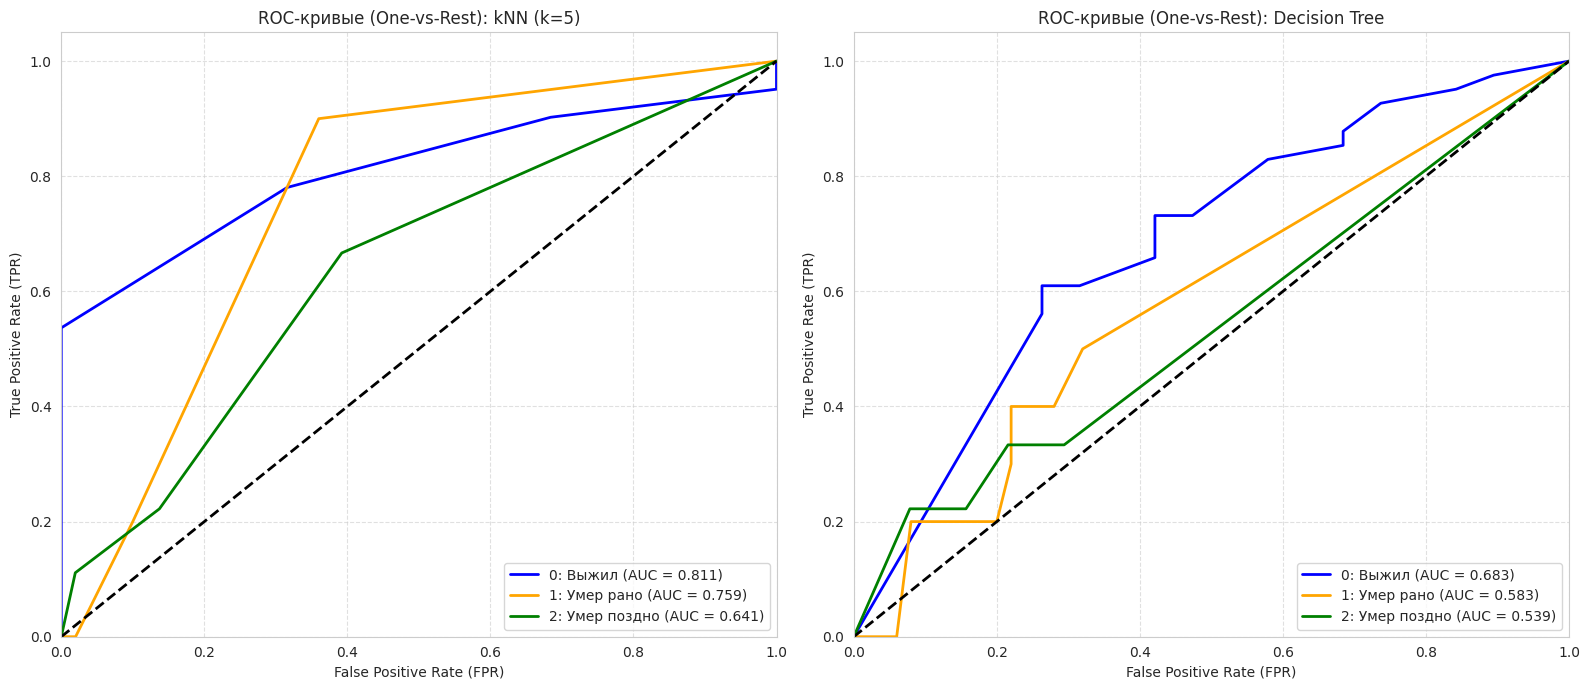

In [76]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

models = [
    ("kNN (k=5)", y_proba_knn, axes[0]),
    ("Decision Tree", y_proba_tree, axes[1])
]

colors = ['blue', 'orange', 'green']
class_names = ['0: Выжил', '1: Умер рано', '2: Умер поздно']

for name, y_proba, ax in models:
    for i, color in zip(range(n_classes), colors):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f'{class_names[i]} (AUC = {roc_auc:.3f})')

    ax.plot([0, 1], [0, 1], color='black', lw=2, linestyle='--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate (FPR)')
    ax.set_ylabel('True Positive Rate (TPR)')
    ax.set_title(f'ROC-кривые (One-vs-Rest): {name}')
    ax.legend(loc="lower right")
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Важность признаков (по версии Decision Tree):


,Признак,Важность
4,ejection_fraction,0.262717
7,serum_creatinine,0.228827
0,age,0.181496
2,creatinine_phosphokinase,0.124740
9,sex,0.047630
3,diabetes,0.043370
6,platelets,0.039500
5,high_blood_pressure,0.038296
8,serum_sodium,0.018745
1,anaemia,0.014679


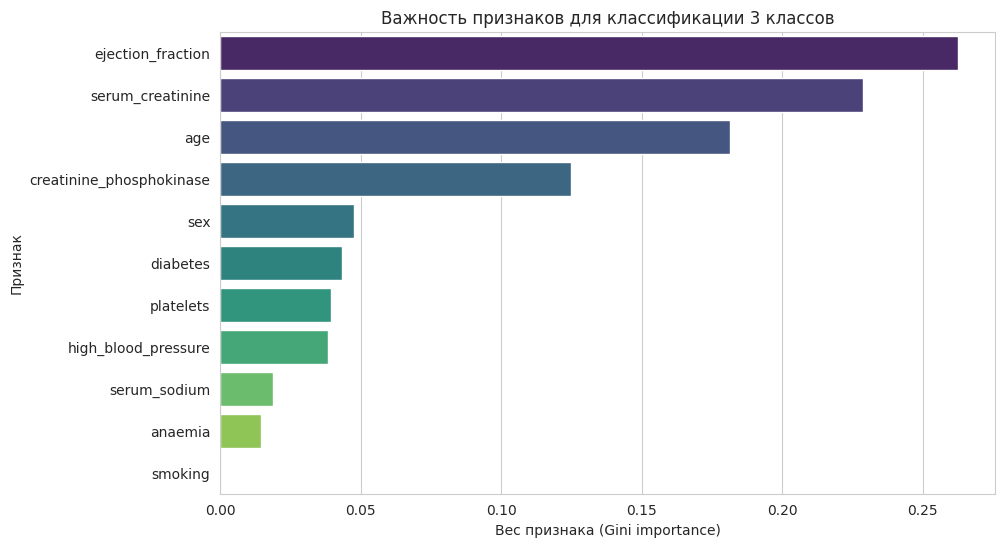

In [77]:
importances = final_tree.feature_importances_
features = X.columns

feature_imp_df = pd.DataFrame({
    'Признак': features,
    'Важность': importances
}).sort_values(by='Важность', ascending=False)

print("Важность признаков (по версии Decision Tree):")
display(feature_imp_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df, x='Важность', y='Признак', palette='viridis')
plt.title('Важность признаков для классификации 3 классов')
plt.xlabel('Вес признака (Gini importance)')
plt.ylabel('Признак')
plt.show()

In [78]:
features_to_drop = ['smoking', 'sex']

X_train_reduced = X_train.drop(columns=features_to_drop)
X_test_reduced = X_test.drop(columns=features_to_drop)

tree_reduced = DecisionTreeClassifier(
    max_depth=7,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

tree_reduced.fit(X_train_reduced, y_train)
y_pred_reduced = tree_reduced.predict(X_test_reduced)

print("--- Дерево решений (Все 11 признаков) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tree):.3f}")
print(f"Macro F1: {f1_score(y_test, y_pred_tree, average='macro'):.3f}")
print(f"Macro Recall: {recall_score(y_test, y_pred_tree, average='macro'):.3f}")

print("\n--- Дерево решений (БЕЗ малозначимых, 9 признаков) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_reduced):.3f}")
print(f"Macro F1: {f1_score(y_test, y_pred_reduced, average='macro'):.3f}")
print(f"Macro Recall: {recall_score(y_test, y_pred_reduced, average='macro'):.3f}")

--- Дерево решений (Все 11 признаков) ---
Accuracy: 0.550
Macro F1: 0.434
Macro Recall: 0.456

--- Дерево решений (БЕЗ малозначимых, 9 признаков) ---
Accuracy: 0.550
Macro F1: 0.434
Macro Recall: 0.456
